In [69]:
# Import necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split 
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report , roc_auc_score , confusion_matrix

In [70]:
# Read and load dataset 

def read_data(filepath):
    try:
        df= pd.read_csv(filepath)
        print("Dataset loaded successfully! \n ")
        return df
    except FileNotFoundError:
        print(f"Error: The file at {filepath} was not found.")
    except pd.errors.EmptyDataError: 
        print("Error: The file is empty.")
    except pd.errors.ParserError:
        print("Error: There was a problem parsing the file.")

In [71]:
# Calling the function

df= read_data(r"D:\Python\pythoncode\heart_disease.csv")
df

Dataset loaded successfully! 
 


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,916,54,Female,VA Long Beach,asymptomatic,127.0,333.0,True,st-t abnormality,154.0,False,0.0,NaN,NaN,NaN,1
916,917,62,Male,VA Long Beach,typical angina,NaN,139.0,False,st-t abnormality,NaN,NaN,NaN,NaN,NaN,NaN,0
917,918,55,Male,VA Long Beach,asymptomatic,122.0,223.0,True,st-t abnormality,100.0,False,0.0,NaN,NaN,fixed defect,2
918,919,58,Male,VA Long Beach,asymptomatic,NaN,385.0,True,lv hypertrophy,NaN,NaN,NaN,NaN,NaN,NaN,0


##### -> Dataset Features Overview:
###### id: Patient_ID
###### age: Age_Years
###### sex: Gender
###### dataset: Origin_Dataset
###### cp: Chest_Pain_Type
###### trestbps: Resting_Blood_Pressure_mmHg
###### chol: Serum_Cholesterol_mg_dl
###### fbs: Fasting_Blood_Sugar
###### restecg: Resting_ECG_Results
###### thalch: Max_Heart_Rate
###### exang: Exercise_Induced_Angina
###### oldpeak: ST_Depression
###### slope: Peak_ST_Segment_Slope
###### ca: Major_Vessels
###### thal: Thalassemia_Status
###### num: Heart_Disease_Severity

In [72]:
# Rename the columns

def rename_columns(dataframe,rename_dict):
    dataframe.rename(columns=rename_dict,inplace=True)
    return dataframe

In [73]:
# Calling the function

df= rename_columns(df,{
   'dataset': 'location',
   'num':'heart_disease'})
print("Renamed Successfully!\n")
df.head()

Renamed Successfully!



,id,age,sex,location,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,heart_disease
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [74]:
# first 5 rows

def first_5_rows(dataframe):
    head= dataframe.head(5)
    return head

In [75]:
# Calling the function

print("First 5 rows of the Dataframe:\n")
first_5_rows(df)

First 5 rows of the Dataframe:



,id,age,sex,location,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,heart_disease
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [76]:
# DataFrame Dimensions

def dimension(dataframe):
    shape= dataframe.shape
    return shape

In [77]:
# Calling the function

print("Dimension of the Dataframe:")
dimension(df)

Dimension of the Dataframe:


(920, 16)

In [78]:
# Counts of Values in the DataFtame

def value_counts(dataframe,columns):
    counts={}
    for i in columns:
        if i in dataframe.columns:
            counts[i]= dataframe[i].value_counts()
        else:
            counts[i] = f"Column '{i}' does not exist in the DataFrame"
    return counts

In [79]:
# Calling the function

v_count= value_counts(df,['sex','heart_disease'])
print(f"Value counts of Column:\n{v_count}")

Value counts of Column:
{'sex': sex
Male      726
Female    194
Name: count, dtype: int64, 'heart_disease': heart_disease
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64}


In [80]:
# DataFrame summary information

def dataframe_summary(dataframe):
    dataframe.info()

In [81]:
# Calling the function 

print("Dataframe summary information: \n")
dataframe_summary(df)

Dataframe summary information: 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             920 non-null    int64  
 1   age            920 non-null    int64  
 2   sex            920 non-null    object 
 3   location       920 non-null    object 
 4   cp             920 non-null    object 
 5   trestbps       861 non-null    float64
 6   chol           890 non-null    float64
 7   fbs            830 non-null    object 
 8   restecg        918 non-null    object 
 9   thalch         865 non-null    float64
 10  exang          865 non-null    object 
 11  oldpeak        858 non-null    float64
 12  slope          611 non-null    object 
 13  ca             309 non-null    float64
 14  thal           434 non-null    object 
 15  heart_disease  920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB


In [82]:
# Dataframe summary statistics

def summary_statistics(dataframe):
    summary_stats= dataframe.describe()
    print(f"Dataframe summary statistics: \n")
    return summary_stats

In [83]:
# Calling the function 

summary_statistics(df)

Dataframe summary statistics: 



,id,age,trestbps,chol,thalch,oldpeak,ca,heart_disease
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


In [84]:
# Check for datatypes

def data_types(dataframe):
    d_types= df.dtypes
    print("Dataframe data types: \n")
    return d_types

In [85]:
# Calling the function 

data_types(df)

Dataframe data types: 



id                 int64
age                int64
sex               object
location          object
cp                object
trestbps         float64
chol             float64
fbs               object
restecg           object
thalch           float64
exang             object
oldpeak          float64
slope             object
ca               float64
thal              object
heart_disease      int64
dtype: object

In [86]:
# Extract Column Names as a List

def column_names(dataframe):
    names= dataframe.columns.tolist()
    return names

In [87]:
# Calling the function

print("Existing column names: ")
column_names(df)

Existing column names: 


['id',
 'age',
 'sex',
 'location',
 'cp',
 'trestbps',
 'chol',
 'fbs',
 'restecg',
 'thalch',
 'exang',
 'oldpeak',
 'slope',
 'ca',
 'thal',
 'heart_disease']

In [88]:
# Drop unncessary columns

def drop_column(dataframe,columns):
   drop= dataframe.drop(columns,axis=1)
   return drop

In [89]:
# Calling the function

df= drop_column(df,['id'])
print("Dropped unncessary columns successfully! \n")
df.head(5)

Dropped unncessary columns successfully! 



,age,sex,location,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,heart_disease
0,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [90]:
# Check for missing values in the DataFrame

def missing_values(dataframe):
    
    # Count NaN/None values
    check_null= dataframe.isnull().sum()

    # Count empty string values
    check_empty= (dataframe=='').sum()
    
    total_missing =  check_null + check_empty
    print("Missing values in the Dataframe: \n")
    return total_missing

In [91]:
# Calling the function

missing_values(df)   

Missing values in the Dataframe: 



age                0
sex                0
location           0
cp                 0
trestbps          59
chol              30
fbs               90
restecg            2
thalch            55
exang             55
oldpeak           62
slope            309
ca               611
thal             486
heart_disease      0
dtype: int64

In [92]:
# Check for unique values in the DataFrame

def check_unique_values(dataframe):
    for i in dataframe.columns:
        print(i,":",dataframe[i].unique())

In [93]:
# Calling the function

print("Unique values in the Dataframe: \n")
check_unique_values(df)

Unique values in the Dataframe: 

age : [63 67 37 41 56 62 57 53 44 52 48 54 49 64 58 60 50 66 43 40 69 59 42 55
 61 65 71 51 46 45 39 68 47 34 35 29 70 77 38 74 76 28 30 31 32 33 36 72
 73 75]
sex : ['Male' 'Female']
location : ['Cleveland' 'Hungary' 'Switzerland' 'VA Long Beach']
cp : ['typical angina' 'asymptomatic' 'non-anginal' 'atypical angina']
trestbps : [145. 160. 120. 130. 140. 172. 150. 110. 132. 117. 135. 112. 105. 124.
 125. 142. 128. 170. 155. 104. 180. 138. 108. 134. 122. 115. 118. 100.
 200.  94. 165. 102. 152. 101. 126. 174. 148. 178. 158. 192. 129. 144.
 123. 136. 146. 106. 156. 154. 114. 164.  98. 190.  nan 113.  92.  95.
  80. 185. 116.   0.  96. 127.]
chol : [233. 286. 229. 250. 204. 236. 268. 354. 254. 203. 192. 294. 256. 263.
 199. 168. 239. 275. 266. 211. 283. 284. 224. 206. 219. 340. 226. 247.
 167. 230. 335. 234. 177. 276. 353. 243. 225. 302. 212. 330. 175. 417.
 197. 198. 290. 253. 172. 273. 213. 305. 216. 304. 188. 282. 185. 232.
 326. 231. 269. 267. 248. 36

In [94]:
# Handling missing values

def handle_categorical_values(dataframe,columns):
        mode= dataframe[columns].mode().iloc[0]
        dataframe[columns]= dataframe[columns].fillna(mode)
        return dataframe[columns]

In [95]:
# Calling the function

print("Filled columns: \n")
handle_categorical_values(df,['fbs','exang','slope','thal','restecg'])

Filled columns: 



C:\Users\oasis computer\AppData\Local\Temp\ipykernel_18384\1118816675.py:5: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dataframe[columns]= dataframe[columns].fillna(mode)


,fbs,exang,slope,thal,restecg
0,True,False,downsloping,fixed defect,lv hypertrophy
1,False,True,flat,normal,lv hypertrophy
2,False,True,flat,reversable defect,lv hypertrophy
3,False,False,downsloping,normal,normal
4,False,False,upsloping,normal,lv hypertrophy
...,...,...,...,...,...
915,True,False,flat,normal,st-t abnormality
916,False,False,flat,normal,st-t abnormality
917,True,False,flat,fixed defect,st-t abnormality
918,True,False,flat,normal,lv hypertrophy


In [96]:
def handle_numerical_values(dataframe,columns):
        mean= dataframe[columns].mean()
        dataframe[columns]= dataframe[columns].fillna(mean)
        return dataframe

In [97]:
# Calling the function

handle_numerical_values(df,['trestbps','chol','thalch','oldpeak','ca'])

,age,sex,location,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,heart_disease
0,63,Male,Cleveland,typical angina,145.000000,233.0,True,lv hypertrophy,150.000000,False,2.300000,downsloping,0.000000,fixed defect,0
1,67,Male,Cleveland,asymptomatic,160.000000,286.0,False,lv hypertrophy,108.000000,True,1.500000,flat,3.000000,normal,2
2,67,Male,Cleveland,asymptomatic,120.000000,229.0,False,lv hypertrophy,129.000000,True,2.600000,flat,2.000000,reversable defect,1
3,37,Male,Cleveland,non-anginal,130.000000,250.0,False,normal,187.000000,False,3.500000,downsloping,0.000000,normal,0
4,41,Female,Cleveland,atypical angina,130.000000,204.0,False,lv hypertrophy,172.000000,False,1.400000,upsloping,0.000000,normal,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,54,Female,VA Long Beach,asymptomatic,127.000000,333.0,True,st-t abnormality,154.000000,False,0.000000,flat,0.676375,normal,1
916,62,Male,VA Long Beach,typical angina,132.132404,139.0,False,st-t abnormality,137.545665,False,0.878788,flat,0.676375,normal,0
917,55,Male,VA Long Beach,asymptomatic,122.000000,223.0,True,st-t abnormality,100.000000,False,0.000000,flat,0.676375,fixed defect,2
918,58,Male,VA Long Beach,asymptomatic,132.132404,385.0,True,lv hypertrophy,137.545665,False,0.878788,flat,0.676375,normal,0


In [98]:
# After handlig missing values 

# Calling the missing values function
missing_values(df)   

Missing values in the Dataframe: 



age              0
sex              0
location         0
cp               0
trestbps         0
chol             0
fbs              0
restecg          0
thalch           0
exang            0
oldpeak          0
slope            0
ca               0
thal             0
heart_disease    0
dtype: int64

In [99]:
# Label encoder for specific categorical columns

def label_encoder(dataframe,columns):
    le= LabelEncoder()
    for i in columns:
        dataframe[i]= le.fit_transform(dataframe[i])
    return dataframe

In [100]:
# Calling the function

print("Label Encoding for Categorical Columns:\n")
label_encoder(df,['sex','location','cp','restecg','exang','slope'])

Label Encoding for Categorical Columns:



,age,sex,location,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,heart_disease
0,63,1,0,3,145.000000,233.0,True,0,150.000000,0,2.300000,0,0.000000,fixed defect,0
1,67,1,0,0,160.000000,286.0,False,0,108.000000,1,1.500000,1,3.000000,normal,2
2,67,1,0,0,120.000000,229.0,False,0,129.000000,1,2.600000,1,2.000000,reversable defect,1
3,37,1,0,2,130.000000,250.0,False,1,187.000000,0,3.500000,0,0.000000,normal,0
4,41,0,0,1,130.000000,204.0,False,0,172.000000,0,1.400000,2,0.000000,normal,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,54,0,3,0,127.000000,333.0,True,2,154.000000,0,0.000000,1,0.676375,normal,1
916,62,1,3,3,132.132404,139.0,False,2,137.545665,0,0.878788,1,0.676375,normal,0
917,55,1,3,0,122.000000,223.0,True,2,100.000000,0,0.000000,1,0.676375,fixed defect,2
918,58,1,3,0,132.132404,385.0,True,0,137.545665,0,0.878788,1,0.676375,normal,0


In [101]:
# One-hot encodig for 'thal' column

def one_hot_encoding(dataframe, column):
    dataframe = pd.get_dummies(dataframe, columns=[column], drop_first=True)
    print("One-Hot_Encoding for 'thal' Column: \n")
    return dataframe

In [102]:
df= one_hot_encoding(df,'thal')
df

One-Hot_Encoding for 'thal' Column: 



,age,sex,location,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,heart_disease,thal_normal,thal_reversable defect
0,63,1,0,3,145.000000,233.0,True,0,150.000000,0,2.300000,0,0.000000,0,False,False
1,67,1,0,0,160.000000,286.0,False,0,108.000000,1,1.500000,1,3.000000,2,True,False
2,67,1,0,0,120.000000,229.0,False,0,129.000000,1,2.600000,1,2.000000,1,False,True
3,37,1,0,2,130.000000,250.0,False,1,187.000000,0,3.500000,0,0.000000,0,True,False
4,41,0,0,1,130.000000,204.0,False,0,172.000000,0,1.400000,2,0.000000,0,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,54,0,3,0,127.000000,333.0,True,2,154.000000,0,0.000000,1,0.676375,1,True,False
916,62,1,3,3,132.132404,139.0,False,2,137.545665,0,0.878788,1,0.676375,0,True,False
917,55,1,3,0,122.000000,223.0,True,2,100.000000,0,0.000000,1,0.676375,2,False,False
918,58,1,3,0,132.132404,385.0,True,0,137.545665,0,0.878788,1,0.676375,0,True,False


In [103]:
# Correlation matrix of the dataframe 

def correlation_matrix(dataframe):
    corr= df.corr()
    return corr

In [104]:
# Calling the function

correlation= correlation_matrix(df)
print("Correlation matrix of the Dataframe: \n")
correlation

Correlation matrix of the Dataframe: 



,age,sex,location,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,heart_disease,thal_normal,thal_reversable defect
age,1.000000,0.056889,0.235076,-0.076519,0.235253,-0.084499,0.219915,-0.006652,-0.353471,0.160910,0.248082,-0.077087,0.204139,0.339596,-0.131861,0.131164
sex,0.056889,1.000000,0.285734,-0.125933,0.001073,-0.193782,0.075370,0.072160,-0.177135,0.155204,0.102733,-0.105805,0.062058,0.259342,-0.153255,0.127775
location,0.235076,0.285734,1.000000,-0.150334,0.019468,-0.412534,0.170110,0.460189,-0.382415,0.129326,0.048533,-0.297152,0.005595,0.276203,0.174956,-0.181553
cp,-0.076519,-0.125933,-0.150334,1.000000,-0.022565,0.064510,0.006370,-0.070150,0.289362,-0.360513,-0.173515,0.113415,-0.124987,-0.314518,0.148695,-0.137850
trestbps,0.235253,0.001073,0.019468,-0.022565,1.000000,0.088290,0.148398,0.015160,-0.104616,0.149040,0.160268,-0.052655,0.051940,0.116225,-0.076348,0.079966
chol,-0.084499,-0.193782,-0.412534,0.064510,0.088290,1.000000,0.089718,-0.199856,0.226325,-0.031472,0.045498,0.034893,0.017544,-0.228238,0.087066,-0.077171
fbs,0.219915,0.075370,0.170110,0.006370,0.148398,0.089718,1.000000,0.025788,-0.030271,-0.003475,0.050344,-0.070830,0.080067,0.129539,-0.064647,0.031461
restecg,-0.006652,0.072160,0.460189,-0.070150,0.015160,-0.199856,0.025788,1.000000,-0.165651,0.026067,-0.030956,-0.128925,-0.057083,0.034603,0.175576,-0.195345
thalch,-0.353471,-0.177135,-0.382415,0.289362,-0.104616,0.226325,-0.030271,-0.165651,1.000000,-0.349828,-0.149630,0.290846,-0.140644,-0.351055,0.107166,-0.089178
exang,0.160910,0.155204,0.129326,-0.360513,0.149040,-0.031472,-0.003475,0.026067,-0.349828,1.000000,0.382073,-0.193716,0.072233,0.350567,-0.205142,0.209128


In [105]:
# Create a heatmap to visualize the correlations

def heat_map(correlation_matrix):
    plt.figure(figsize=(14, 12))
    sns.heatmap(correlation_matrix,annot=True,cmap='coolwarm', fmt='.2f')
    plt.title('Correlation Heatmap')
    plt.xticks(rotation=90)
    plt.show()

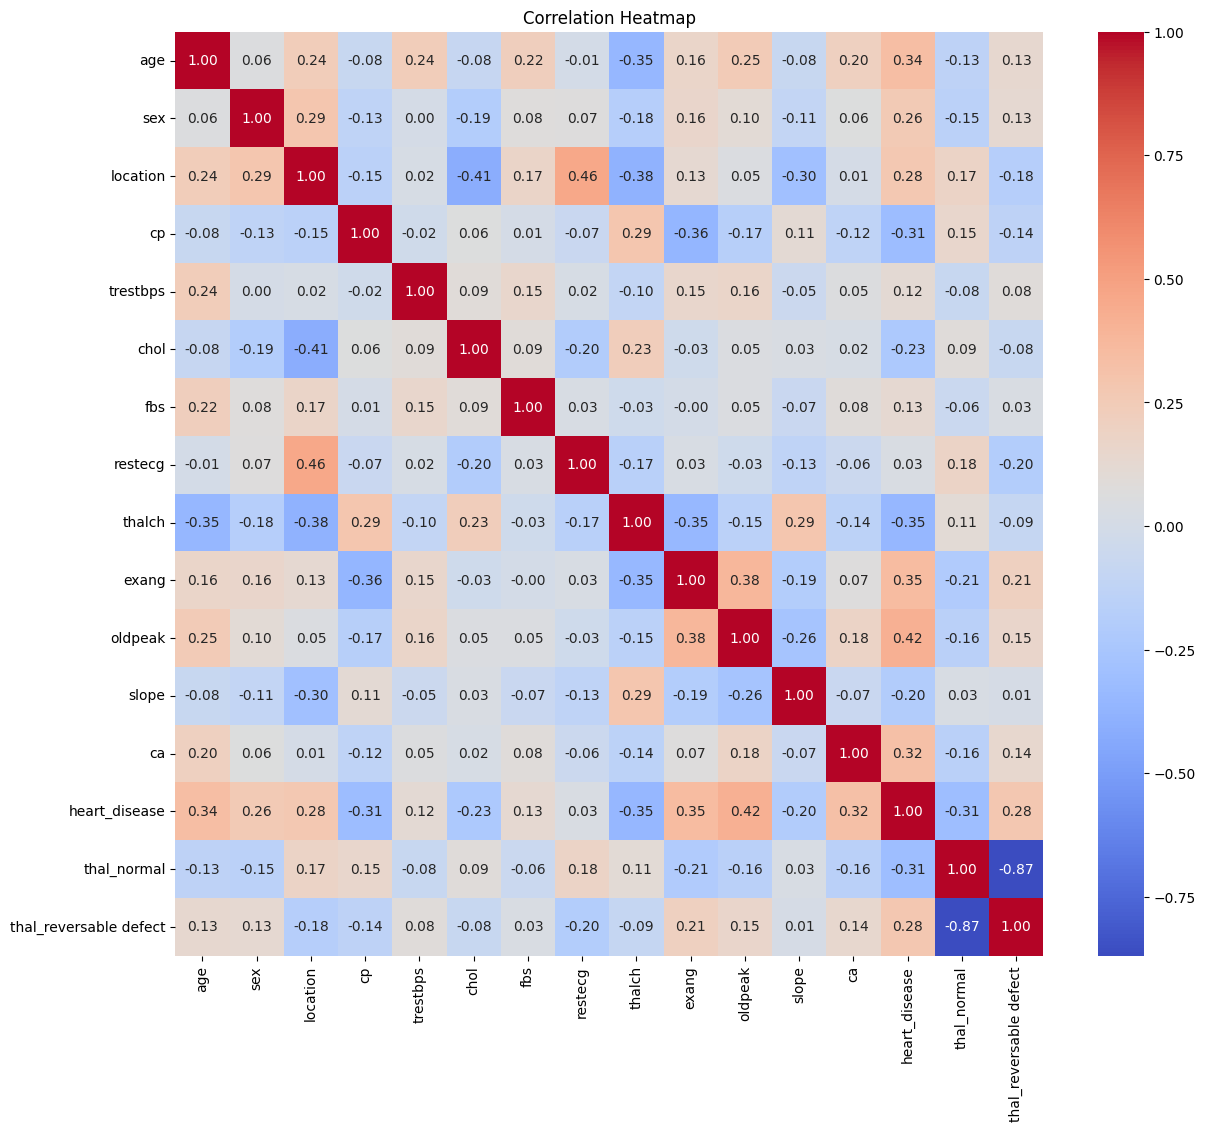

In [106]:
# Calling the function

heat_map(correlation)

In [107]:
# Creating a box plot to visualize heart disease distribution by gender

def barplot(dataframe,x,y,figsize=(8, 6),legend=None,title=None, xlabel=None,ylabel= None,xticks_rotation=0):
    plt.figure(figsize=(10, 8))
    sns.barplot(x=x,y=y,data=dataframe)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel) 
    plt.legend(legend,loc='upper left', frameon=True, edgecolor='black', facecolor='lightgray')
    plt.xticks(rotation = xticks_rotation)
    plt.show()

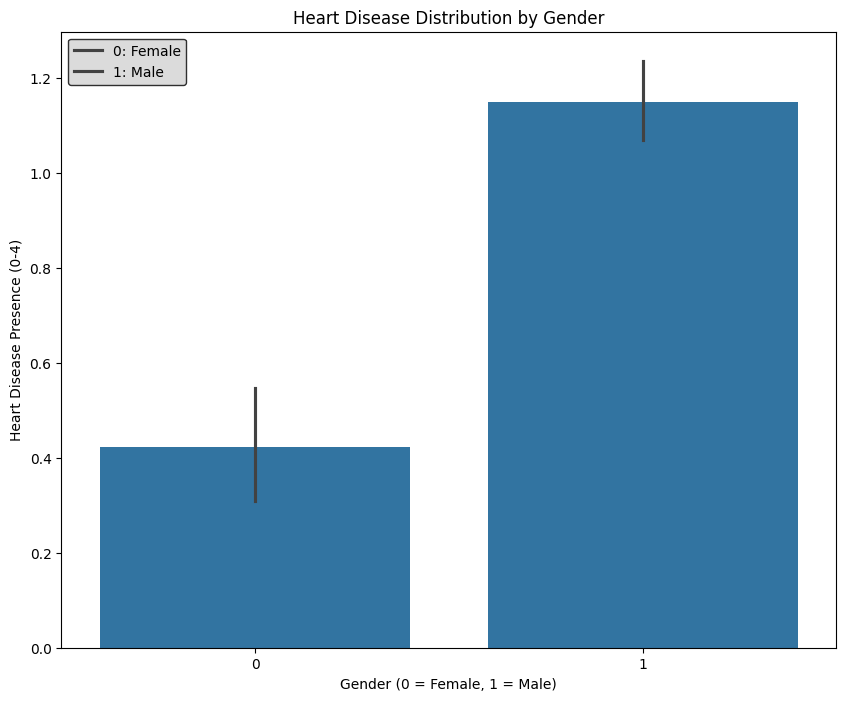

In [108]:
# Calling the function

barplot(df,'sex','heart_disease',
        figsize= (10,8),
        legend=['0: Female', '1: Male'],
        title='Heart Disease Distribution by Gender', 
        xlabel='Gender (0 = Female, 1 = Male)', 
        ylabel='Heart Disease Presence (0-4)')

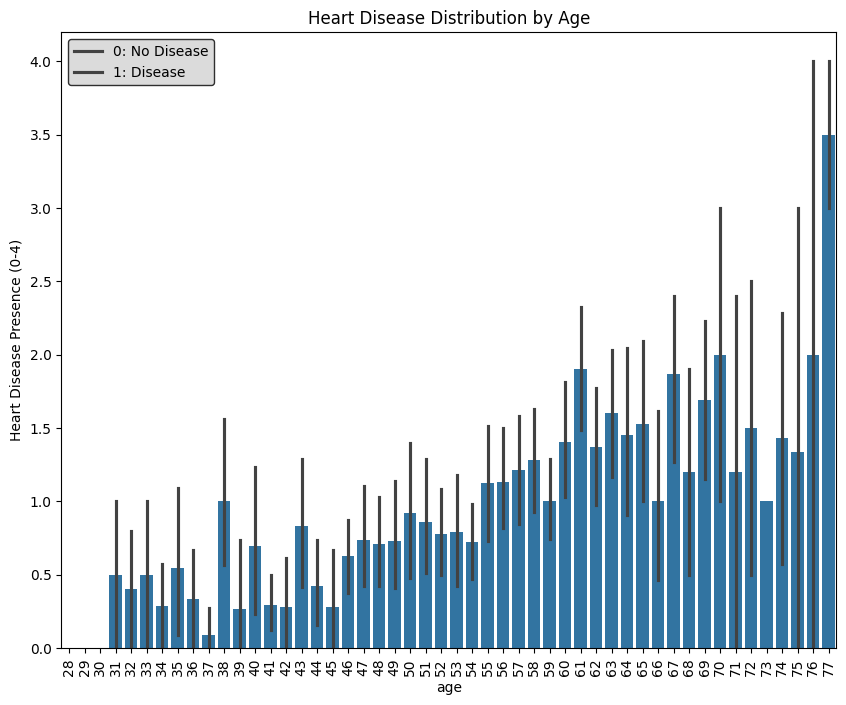

In [42]:
# Calling the function

barplot(df,'age','heart_disease',
        figsize= (18,16),
        title='Heart Disease Distribution by Age', 
        legend=['0: No Disease', '1: Disease'],
        xlabel='age', 
        ylabel='Heart Disease Presence (0-4)',
        xticks_rotation=90)

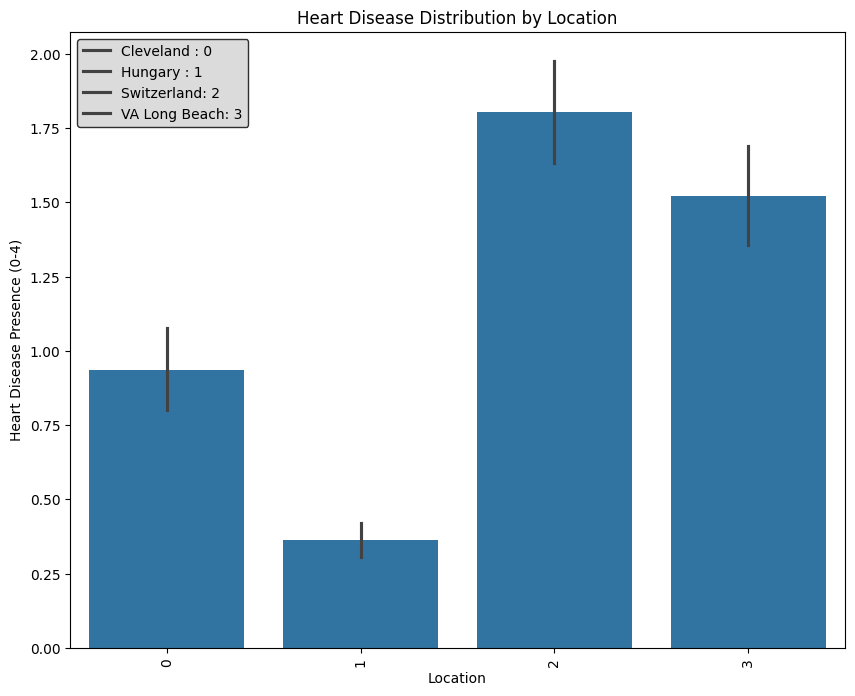

In [110]:
# Calling the function

barplot(df,'location','heart_disease',
        figsize= (14,10),
        title='Heart Disease Distribution by Location', 
        legend=['Cleveland : 0', 'Hungary : 1', 'Switzerland: 2', 'VA Long Beach: 3'],
        xlabel='Location', 
        ylabel='Heart Disease Presence (0-4)',
        xticks_rotation=90)

In [111]:
df.head()

,age,sex,location,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,heart_disease,thal_normal,thal_reversable defect
0,63,1,0,3,145.0,233.0,True,0,150.0,0,2.3,0,0.0,0,False,False
1,67,1,0,0,160.0,286.0,False,0,108.0,1,1.5,1,3.0,2,True,False
2,67,1,0,0,120.0,229.0,False,0,129.0,1,2.6,1,2.0,1,False,True
3,37,1,0,2,130.0,250.0,False,1,187.0,0,3.5,0,0.0,0,True,False
4,41,0,0,1,130.0,204.0,False,0,172.0,0,1.4,2,0.0,0,True,False


In [112]:
# Define features and targets 

def features_and_target(dataframe,features,target):
    X = dataframe[features]
    y = dataframe[target]

    print("Features (X):")
    print(X.head())  # Print the first few rows of features
    
    print("\nTarget (y):")
    print(y.head())  # Print the first few rows of the target

    return X,y

In [113]:
# Calling the function

X,y= features_and_target(df,['age', 'sex', 'location', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
       'thalch', 'exang', 'oldpeak', 'slope', 'ca','thal_normal', 'thal_reversable defect'],'heart_disease')

Features (X):
   age  sex  location  cp  trestbps   chol    fbs  restecg  thalch  exang  \
0   63    1         0   3     145.0  233.0   True        0   150.0      0   
1   67    1         0   0     160.0  286.0  False        0   108.0      1   
2   67    1         0   0     120.0  229.0  False        0   129.0      1   
3   37    1         0   2     130.0  250.0  False        1   187.0      0   
4   41    0         0   1     130.0  204.0  False        0   172.0      0   

   oldpeak  slope   ca  thal_normal  thal_reversable defect  
0      2.3      0  0.0        False                   False  
1      1.5      1  3.0         True                   False  
2      2.6      1  2.0        False                    True  
3      3.5      0  0.0         True                   False  
4      1.4      2  0.0         True                   False  

Target (y):
0    0
1    2
2    1
3    0
4    0
Name: heart_disease, dtype: int64


In [114]:
# Splitting the data

def splitting_data(X,y):
    X_train , X_test , y_train , y_test = train_test_split (X , y, test_size = 0.2, random_state =42)
    return X_train , X_test , y_train , y_test

In [115]:
X_train , X_test , y_train , y_test = splitting_data (X,y)

In [116]:
# Standard Scaler

def standard_scaler(X_train , X_test):
    scaler= StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    return X_train_scaled , X_test_scaled

In [117]:
# Calling the function

X_train_scaled,X_test_scaled = standard_scaler(X_train,X_test)

In [118]:
# Function for Logistic Regression 

def logistic_regression(X_train , X_test , y_train , y_test):
    
    LR_model= LogisticRegression()
    
    LR_model.fit(X_train , y_train)
    
    LR_y_predict = LR_model.predict(X_test)
    print(f"* Logistic Regression Predictions:\n{ LR_y_predict}\n")

    # Evaluate the model using classification 
    
    evaluation_metrics = classification_report( y_test, LR_y_predict )
    print(f"* Classification Report:\n{evaluation_metrics}\n")

    # Confusion matrix

    cf_matrix= confusion_matrix (y_test , LR_y_predict)
    print(f" Confusion matrix : \n {cf_matrix} \n ")
    # Get Predictions and Calculate ROC-AUC 

    y_scores= LR_model.predict_proba (X_test)
    roc_auc = roc_auc_score(y_test, y_scores,multi_class='ovr')
    print(f"* ROC AUC: {roc_auc:.2f}")

In [119]:
# Calling the function 

logistic_regression(X_train , X_test , y_train , y_test)

* Logistic Regression Predictions:
[0 0 1 3 0 0 0 1 1 0 0 1 1 0 1 0 0 0 0 1 0 0 1 1 1 1 1 0 0 0 0 0 0 0 0 1 0
 0 1 0 1 0 0 0 0 1 1 0 0 0 1 0 0 1 0 1 1 0 1 1 0 0 3 1 0 1 0 1 1 0 1 0 1 0
 0 0 0 1 0 0 0 1 0 0 1 1 1 1 0 1 1 1 0 0 0 1 0 1 0 0 1 1 0 1 0 0 0 0 1 0 0
 1 1 0 0 0 1 0 1 0 0 1 0 1 1 0 0 0 1 0 0 0 0 0 1 0 0 1 1 1 1 1 1 1 1 1 1 1
 0 1 1 1 1 0 0 0 0 1 1 0 1 1 0 0 0 1 0 1 0 1 1 0 0 0 0 1 0 1 0 0 1 0 0 1]

* Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.89      0.76        75
           1       0.38      0.56      0.45        54
           2       0.00      0.00      0.00        25
           3       1.00      0.08      0.14        26
           4       0.00      0.00      0.00         4

    accuracy                           0.54       184
   macro avg       0.41      0.31      0.27       184
weighted avg       0.52      0.54      0.46       184


 Confusion matrix : 
 [[67  8  0  0  0]
 [24 30  0  0  0]
 [ 5 20  0  0  0]

D:\Python\bia_env\lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
D:\Python\bia_env\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
D:\Python\bia_env\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted sampl

In [120]:
# Function for Decision Tree Classifier 

def decision_tree(X_train , X_test , y_train , y_test):
    
    DTR_model= DecisionTreeClassifier()
    
    DTR_model.fit(X_train , y_train)
    
    DTR_y_predict = DTR_model.predict(X_test)
    print(f"* Decision Tree Classifier Predictions:\n{ DTR_y_predict}\n")

    # Evaluate the model using classification 
    
    evaluation_metrics = classification_report( y_test, DTR_y_predict )
    print(f"* Classification Report:\n{evaluation_metrics}\n")

    # Confusion matrix

    cf_matrix= confusion_matrix (y_test ,DTR_y_predict)
    print(f" Confusion matrix : \n {cf_matrix} \n ")
    
    # Get Predictions and Calculate ROC-AUC 

    y_scores= DTR_model.predict_proba (X_test)
    roc_auc = roc_auc_score(y_test, y_scores,multi_class='ovr')
    print(f"* ROC AUC: {roc_auc:.2f}")

In [121]:
# Calling the function 

decision_tree(X_train , X_test , y_train , y_test)

* Decision Tree Classifier Predictions:
[0 0 1 4 0 0 0 3 0 0 4 3 3 2 1 1 0 0 0 2 0 0 1 2 3 0 1 0 3 0 1 2 0 1 0 2 0
 1 2 0 0 0 3 0 0 1 1 4 2 0 1 0 0 1 0 0 3 0 0 1 0 0 2 3 0 1 0 0 1 3 3 0 1 0
 0 0 1 1 0 0 0 1 0 2 1 4 2 3 2 3 0 4 0 1 0 0 0 1 0 0 0 2 0 1 0 1 1 0 2 0 1
 1 4 1 1 0 0 0 1 0 0 2 0 0 3 0 2 0 1 1 0 0 0 0 0 0 0 4 2 0 2 1 2 3 2 1 3 4
 0 1 1 1 3 0 0 2 3 1 1 0 0 2 1 0 1 1 0 1 0 1 0 0 0 0 0 2 0 1 0 1 2 3 0 1]

* Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.84      0.77        75
           1       0.49      0.43      0.46        54
           2       0.26      0.24      0.25        25
           3       0.22      0.15      0.18        26
           4       0.12      0.25      0.17         4

    accuracy                           0.53       184
   macro avg       0.36      0.38      0.37       184
weighted avg       0.50      0.53      0.51       184


 Confusion matrix : 
 [[63  6  3  3  0]
 [17 23 10  3  1]
 [ 4  7  6  

In [122]:
# Function for Random Forest Classifier 

def random_forest_classifier(X_train , X_test , y_train , y_test):
    
    RFC_model= RandomForestClassifier()
    
    RFC_model.fit(X_train , y_train)
    
    RFC_y_predict = RFC_model.predict(X_test)
    print(f"* Random Forest Classifier Predictions:\n{ RFC_y_predict}\n")

    # Evaluate the model using classification 
    
    evaluation_metrics = classification_report( y_test, RFC_y_predict )
    print(f"* Classification Report:\n{evaluation_metrics}\n")

    # Confusion matrix

    cf_matrix= confusion_matrix (y_test , RFC_y_predict)
    print(f" Confusion matrix : \n {cf_matrix} \n ")
    
    # Get Predictions and Calculate ROC-AUC 

    y_scores= RFC_model.predict_proba (X_test)
    roc_auc = roc_auc_score(y_test, y_scores,multi_class='ovr')
    print(f"* ROC AUC: {roc_auc:.2f}")

In [123]:
# Calling the function 

random_forest_classifier(X_train , X_test , y_train , y_test)

* Random Forest Classifier Predictions:
[0 0 1 1 1 0 0 3 2 0 1 1 1 1 1 0 0 0 0 1 0 0 1 1 3 1 1 0 0 0 0 0 0 1 0 3 0
 1 0 0 3 0 2 0 0 1 1 4 1 0 2 0 0 0 0 3 3 0 1 1 0 0 1 3 0 2 0 0 1 4 2 0 1 0
 0 0 0 1 0 0 0 0 0 1 1 4 2 3 1 3 1 1 0 0 0 1 0 1 0 0 0 0 0 1 0 0 2 0 2 0 1
 1 1 0 0 0 2 0 1 0 0 1 0 1 3 0 1 0 1 1 0 0 0 0 1 0 0 0 1 0 2 1 1 1 0 1 3 1
 0 1 1 1 2 1 0 0 0 1 2 0 1 3 1 0 0 1 0 3 0 1 1 0 0 0 0 1 0 1 1 0 4 1 0 1]

* Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.91      0.81        75
           1       0.48      0.56      0.51        54
           2       0.42      0.20      0.27        25
           3       0.38      0.19      0.26        26
           4       0.25      0.25      0.25         4

    accuracy                           0.59       184
   macro avg       0.45      0.42      0.42       184
weighted avg       0.56      0.59      0.56       184


 Confusion matrix : 
 [[68  5  2  0  0]
 [18 30  5  0  1]
 [ 1 12  5  

In [124]:
# Function for Support Vector Machines

def support_vector_machine(X_train , X_test , y_train , y_test, kernel_type):
    
    SVM_model= SVC(kernel = kernel_type , probability = True)
    
    SVM_model.fit(X_train , y_train)
    
    SVM_y_predict = SVM_model.predict(X_test)
    print(f"* Support Vector Machines Predictions:\n{ SVM_y_predict}\n")

    # Evaluate the model using classification 
    
    evaluation_metrics = classification_report( y_test, SVM_y_predict )
    print(f"* Classification Report:\n{evaluation_metrics}\n")

    # Confusion matrix

    cf_matrix= confusion_matrix (y_test , SVM_y_predict)
    print(f" Confusion matrix : \n {cf_matrix} \n ")
    
    # Get Predictions and Calculate ROC-AUC 

    y_scores= SVM_model.predict_proba (X_test)
    roc_auc = roc_auc_score (y_test, y_scores,multi_class='ovr')
    print(f"* ROC AUC: {roc_auc:.2f}")

In [125]:
# Calling the function 

support_vector_machine(X_train , X_test , y_train , y_test,kernel_type='linear')

* Support Vector Machines Predictions:
[0 0 1 1 0 0 0 3 0 0 1 1 1 1 1 0 0 0 0 1 0 0 1 1 1 3 1 0 0 0 0 0 0 1 0 0 0
 0 1 0 1 0 0 0 1 1 1 1 1 0 1 0 0 0 0 1 1 0 3 1 0 0 1 1 0 1 0 0 1 0 3 0 1 0
 0 0 0 0 0 0 0 0 0 0 1 3 1 1 1 1 0 1 0 0 0 1 0 1 0 0 1 1 1 1 0 0 1 0 1 0 1
 1 1 0 0 0 1 0 1 0 0 1 0 1 1 0 0 0 1 0 0 0 0 0 1 0 0 1 1 0 3 1 0 1 1 1 3 1
 0 1 1 1 2 0 0 0 0 1 1 0 1 1 0 0 0 1 0 1 0 1 1 0 0 0 0 1 0 1 1 0 1 0 0 1]

* Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.92      0.79        75
           1       0.38      0.54      0.45        54
           2       1.00      0.04      0.08        25
           3       0.00      0.00      0.00        26
           4       0.00      0.00      0.00         4

    accuracy                           0.54       184
   macro avg       0.41      0.30      0.26       184
weighted avg       0.53      0.54      0.46       184


 Confusion matrix : 
 [[69  6  0  0  0]
 [22 29  0  3  0]
 [ 4 17  1  3

D:\Python\bia_env\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
D:\Python\bia_env\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
D:\Python\bia_env\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [126]:
# Calling the function 

support_vector_machine(X_train , X_test , y_train , y_test,kernel_type='poly')

* Support Vector Machines Predictions:
[0 0 1 1 1 0 0 1 1 0 0 0 1 1 1 0 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 0 0 0 0 0 0
 1 0 1 1 0 1 1 0 0 1 0 0 0 1 0 0 0 0 1 1 0 1 1 0 0 1 1 0 0 0 0 0 0 0 0 1 0
 0 0 0 0 0 0 1 0 1 0 0 1 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0
 0 0 0 0 0 1 0 0 0 0 1 0 0 1 0 1 1 1 1 1 0 0 0 1 0 0 0 1 0 0 1 0 1 0 0 0 1
 0 1 1 1 0 0 0 0 0 0 1 0 1 0 0 0 1 1 0 1 0 0 0 0 0 0 0 0 0 1 1 0 0 1 0 1]

* Classification Report:
              precision    recall  f1-score   support

           0       0.54      0.92      0.68        75
           1       0.41      0.43      0.42        54
           2       0.00      0.00      0.00        25
           3       0.00      0.00      0.00        26
           4       0.00      0.00      0.00         4

    accuracy                           0.50       184
   macro avg       0.19      0.27      0.22       184
weighted avg       0.34      0.50      0.40       184


 Confusion matrix : 
 [[69  6  0  0  0]
 [31 23  0  0  0]
 [13 12  0  0

D:\Python\bia_env\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
D:\Python\bia_env\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
D:\Python\bia_env\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [60]:
# Calling the function 

support_vector_machine(X_train , X_test , y_train , y_test,kernel_type='rbf')

* Support Vector Machines Predictions:
[0 0 0 0 0 0 0 1 1 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 0 0 0 0 0 0
 0 0 0 1 0 1 0 0 0 1 0 0 0 1 0 0 0 0 1 1 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 1 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0
 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 1 0 1 1 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 1
 0 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 1]

* Classification Report:
              precision    recall  f1-score   support

           0       0.48      0.97      0.65        75
           1       0.27      0.17      0.21        54
           2       0.00      0.00      0.00        25
           3       0.00      0.00      0.00        26
           4       0.00      0.00      0.00         4

    accuracy                           0.45       184
   macro avg       0.15      0.23      0.17       184
weighted avg       0.28      0.45      0.32       184


 Confusion matrix : 
 [[73  2  0  0  0]
 [45  9  0  0  0]
 [14 11  0  0

D:\Python\bia_env\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
D:\Python\bia_env\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
D:\Python\bia_env\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [127]:
# Calling the function 

support_vector_machine(X_train , X_test , y_train , y_test,kernel_type='sigmoid')

* Support Vector Machines Predictions:
[0 0 0 0 1 0 0 1 1 0 0 0 0 1 1 0 0 1 0 0 0 0 0 0 1 1 1 0 0 0 0 0 1 0 0 0 0
 1 0 0 1 0 1 0 0 0 1 0 1 0 1 0 0 0 0 1 1 0 0 1 0 0 1 1 0 0 1 0 0 0 0 1 1 0
 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 1 0 0 0 0 0 0 0 0 1 1 0 0 0
 0 1 0 0 0 1 0 0 0 0 1 0 0 1 0 1 0 1 1 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1
 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 1]

* Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.89      0.64        75
           1       0.33      0.30      0.31        54
           2       0.00      0.00      0.00        25
           3       0.00      0.00      0.00        26
           4       0.00      0.00      0.00         4

    accuracy                           0.45       184
   macro avg       0.16      0.24      0.19       184
weighted avg       0.30      0.45      0.35       184


 Confusion matrix : 
 [[67  8  0  0  0]
 [38 16  0  0  0]
 [13 12  0  0

D:\Python\bia_env\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
D:\Python\bia_env\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
D:\Python\bia_env\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [128]:
# Function for K-Nearest Neighbors
import joblib
def k_nearest_neighbors(X_train , X_test , y_train , y_test):

    KNN_model = KNeighborsClassifier(n_neighbors = 5)
    KNN_model.fit (X_train,y_train)
    KNN_y_predict = KNN_model.predict ( X_test )
    print(f"* K-Nearest Neighbors Predictions:\n{ KNN_y_predict}\n")

    # Evaluate the model using classification 
    
    evaluation_metrics = classification_report( y_test, KNN_y_predict )
    print(f"* Classification Report:\n{evaluation_metrics}\n")

    # Confusion matrix

    cf_matrix= confusion_matrix (y_test , KNN_y_predict)
    print(f" Confusion matrix : \n {cf_matrix} \n ")
    
    # Get Predictions and Calculate ROC-AUC 

    y_scores= KNN_model.predict_proba (X_test)
    roc_auc = roc_auc_score (y_test, y_scores,multi_class='ovr')
    print(f"* ROC AUC: {roc_auc:.2f}")

In [129]:
# Calling the function

k_nearest_neighbors(X_train , X_test , y_train , y_test)

* K-Nearest Neighbors Predictions:
[0 1 0 0 0 0 0 1 1 2 0 0 0 1 1 0 0 0 0 0 0 2 0 0 0 1 2 1 2 0 0 0 0 0 0 0 0
 1 1 1 1 1 2 0 0 0 2 0 0 0 1 0 0 0 0 1 1 0 1 1 0 0 2 0 0 0 1 0 1 2 0 0 1 0
 0 0 1 1 0 1 1 0 1 0 0 1 0 0 0 4 0 4 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 0 1
 1 0 1 3 1 1 0 0 0 0 1 0 0 2 0 2 1 2 0 0 0 0 0 2 0 0 0 3 2 0 1 0 1 3 0 0 1
 0 2 1 1 0 0 0 1 0 0 1 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 2 0 0 1 0 1 1 0 1]

* Classification Report:
              precision    recall  f1-score   support

           0       0.53      0.81      0.64        75
           1       0.35      0.30      0.32        54
           2       0.12      0.08      0.10        25
           3       0.33      0.04      0.07        26
           4       0.50      0.25      0.33         4

    accuracy                           0.44       184
   macro avg       0.36      0.30      0.29       184
weighted avg       0.39      0.44      0.38       184


 Confusion matrix : 
 [[61 12  2  0  0]
 [26 16 10  2  0]
 [15  8  2  0  0]